## 1. Imports and paths
We keep all ML code in this notebook. The frontend, backend, and Docker configuration are separate because they are application services, not model-training steps.

In [8]:
from pathlib import Path
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from xgboost import XGBClassifier
from sklearn.metrics import (
    average_precision_score, precision_recall_curve, classification_report,
    confusion_matrix, ConfusionMatrixDisplay, precision_score,
    recall_score, f1_score
)

RANDOM_STATE = 42
FEATURES = ["Time"] + [f"V{i}" for i in range(1, 29)] + ["Amount"]
TARGET = "Class"

# Works when VS Code opens the notebook from the root or its parent folder.
PROJECT_ROOT = Path.cwd().resolve()
if not (PROJECT_ROOT / "docker-compose.yml").exists():
    if (PROJECT_ROOT.parent / "docker-compose.yml").exists():
        PROJECT_ROOT = PROJECT_ROOT.parent
    else:
        raise FileNotFoundError("Open the FraudShield project folder in VS Code first.")

DATA_FILE = PROJECT_ROOT / "data" / "creditcard.csv"
ARTIFACT_DIR = PROJECT_ROOT / "artifacts"
ARTIFACT_DIR.mkdir(parents=True, exist_ok=True)
print("Project root:", PROJECT_ROOT)
print("Dataset:", DATA_FILE)
if not DATA_FILE.exists():
    raise FileNotFoundError("Download creditcard.csv from Kaggle and place it in data/creditcard.csv")

Project root: D:\Machine-learning-project\FraudShield-AI-One-Notebook
Dataset: D:\Machine-learning-project\FraudShield-AI-One-Notebook\data\creditcard.csv


In [7]:
%pip install joblib
%pip install numpy pandas matplotlib scikit-learn xgboost shap joblib ipykernel

Note: you may need to restart the kernel to use updated packages.
  Using cached xgboost-3.4.1-py3-none-win_amd64.whl.metadata (2.0 kB)
  Using cached shap-0.54.1-cp312-abi3-win_amd64.whl.metadata (23 kB)
  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
  Using cached narwhals-2.28.0-py3-none-any.whl.metadata (15 kB)
  Using cached threadpoolctl-3.7.0-py3-none-any.whl.metadata (24 kB)
  Using cached tqdm-4.70.1-py3-none-any.whl.metadata (57 kB)
  Using cached slicer-0.0.8-py3-none-any.whl.metadata (4.0 kB)
   ---------------------------------------- 0.0/12.7 MB ? eta -:--:--
   ------------------------ --------------- 7.9/12.7 MB 39.6 MB/s eta 0:00:01
   ---------------------------------------- 12.7/12.7 MB 33.3 MB/s  0:00:00
   ---------------------------------------- 0.0/10.9 MB ? eta -:--:--
   --------------------------- ------------ 7.6/10.9 MB 35.7 MB/s eta 0:00:01
   ---------------------------------------- 10.9/10.9 MB 32.4 MB/s  0:00:00
   ----------------------

## 2. Load the dataset
`Class=0` means genuine transaction, `Class=1` means fraud in this dataset. Validate columns before training.

In [9]:
df = pd.read_csv(DATA_FILE)
missing_columns = [col for col in FEATURES + [TARGET] if col not in df.columns]
if missing_columns:
    raise ValueError(f"Dataset columns missing: {missing_columns}")

df = df[FEATURES + [TARGET]].dropna().copy()
if not set(df[TARGET].unique()).issubset({0, 1}) or df[TARGET].nunique() != 2:
    raise ValueError("Class must have values 0 and 1, with both classes present")
if not np.isfinite(df[FEATURES].to_numpy(dtype=float)).all():
    raise ValueError("Dataset contains infinite values")
print("Dataset shape:", df.shape)
display(df.head())
display(df.isna().sum().to_frame("missing_values").T)

Dataset shape: (284807, 31)


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
missing_values,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


## 3. EDA — class imbalance and amount distribution
**Accuracy alone can be misleading**: on very imbalanced data, a model that predicts everything as genuine might still achieve very high accuracy.

Class counts: 0 = genuine, 1 = fraud


,transactions
Class,
0,284315
1,492


Fraud percentage: 0.1727%


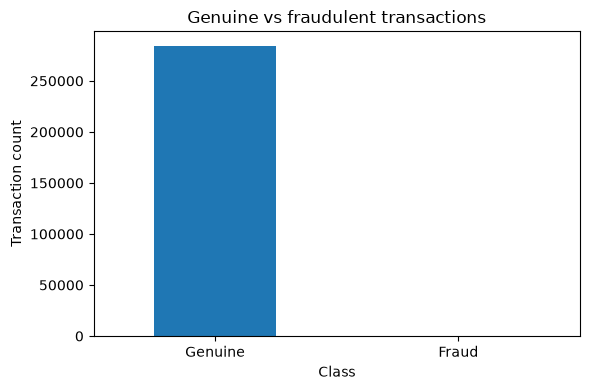

,count,mean,std,min,25%,50%,75%,max
Class,,,,,,,,
0,284315.0,88.291022,250.105092,0.0,5.65,22.00,77.05,25691.16
1,492.0,122.211321,256.683288,0.0,1.00,9.25,105.89,2125.87


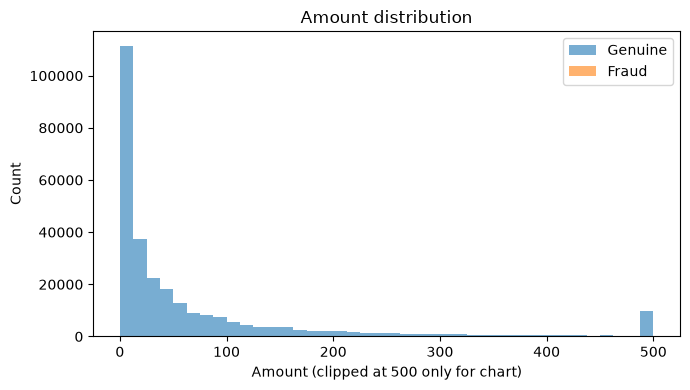

In [10]:
class_counts = df[TARGET].value_counts().sort_index()
print("Class counts: 0 = genuine, 1 = fraud")
display(class_counts.to_frame("transactions"))
print(f"Fraud percentage: {100 * (df[TARGET] == 1).mean():.4f}%")

fig, ax = plt.subplots(figsize=(6, 4))
class_counts.rename(index={0: "Genuine", 1: "Fraud"}).plot(kind="bar", ax=ax)
ax.set_title("Genuine vs fraudulent transactions")
ax.set_xlabel("Class")
ax.set_ylabel("Transaction count")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

display(df.groupby("Class")["Amount"].describe())
# Plot is limited to a readable amount range without changing training data.
fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(df.loc[df.Class.eq(0), "Amount"].clip(upper=500), bins=40, alpha=0.6, label="Genuine")
ax.hist(df.loc[df.Class.eq(1), "Amount"].clip(upper=500), bins=40, alpha=0.6, label="Fraud")
ax.set(xlabel="Amount (clipped at 500 only for chart)", ylabel="Count", title="Amount distribution")
ax.legend()
plt.tight_layout()
plt.show()

## 4. Train / validation / test split (60% / 20% / 20%)
Stratified split preserves the fraud proportion. **The test set must not influence model choice or classification threshold.** This is a retrospective random split, not a time-forward production evaluation.

In [11]:
X = df[FEATURES]
y = df[TARGET].astype(int)
if y.value_counts().min() < 10:
    raise ValueError("At least 10 observations of each class are needed for a useful demo split")

X_train, X_remaining, y_train, y_remaining = train_test_split(
    X, y, test_size=0.40, stratify=y, random_state=RANDOM_STATE
)
X_valid, X_test, y_valid, y_test = train_test_split(
    X_remaining, y_remaining, test_size=0.50,
    stratify=y_remaining, random_state=RANDOM_STATE
)
print(f"Train: {len(X_train):,} | Validation: {len(X_valid):,} | Test: {len(X_test):,}")
print("Fraud counts:", {"train": int(y_train.sum()), "validation": int(y_valid.sum()), "test": int(y_test.sum())})

Train: 170,884 | Validation: 56,961 | Test: 56,962
Fraud counts: {'train': 295, 'validation': 98, 'test': 99}


## 5. Train two ML models
Logistic Regression uses a pipeline with `StandardScaler` fitted **only on the training split**. XGBoost handles non-linear patterns. Both address rare fraud using class weights / positive-class weighting.

In [12]:
negative_count = int((y_train == 0).sum())
positive_count = int((y_train == 1).sum())

models = {
    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", LogisticRegression(
            max_iter=1500, class_weight="balanced", random_state=RANDOM_STATE
        )),
    ]),
    "XGBoost": XGBClassifier(
        n_estimators=250,
        max_depth=4,
        learning_rate=0.05,
        subsample=0.85,
        colsample_bytree=0.85,
        scale_pos_weight=negative_count / positive_count,
        objective="binary:logistic",
        eval_metric="aucpr",
        random_state=RANDOM_STATE,
        n_jobs=4,
        tree_method="hist",
    ),
}

trained_models = {}
for name, model in models.items():
    print(f"Training: {name}")
    model.fit(X_train, y_train)
    trained_models[name] = model
print("Training complete.")

Training: Logistic Regression
Training: XGBoost
Training complete.


## 6. Compare models on validation data
Use **PR-AUC (Average Precision)** as the primary selection metric; choose the decision threshold using validation F1. The dashboard will use this stored threshold, not automatically use `0.50`.

In [13]:
def find_best_f1_threshold(labels, probabilities):
    precision, recall, thresholds = precision_recall_curve(labels, probabilities)
    f1_values = 2 * precision[:-1] * recall[:-1] / np.maximum(
        precision[:-1] + recall[:-1], 1e-12
    )
    best_index = int(np.argmax(f1_values))
    return float(thresholds[best_index]), float(f1_values[best_index])

validation_results = {}
for name, model in trained_models.items():
    probs = model.predict_proba(X_valid)[:, 1]
    threshold, best_f1 = find_best_f1_threshold(y_valid, probs)
    labels = (probs >= threshold).astype(int)
    validation_results[name] = {
        "validation_pr_auc": float(average_precision_score(y_valid, probs)),
        "validation_f1": best_f1,
        "threshold": threshold,
        "validation_precision": float(precision_score(y_valid, labels, zero_division=0)),
        "validation_recall": float(recall_score(y_valid, labels, zero_division=0)),
    }
comparison = pd.DataFrame.from_dict(validation_results, orient="index").sort_values(
    "validation_pr_auc", ascending=False
)
display(comparison.round(4))

winner = max(
    validation_results,
    key=lambda name: (
        validation_results[name]["validation_pr_auc"],
        validation_results[name]["validation_f1"],
    ),
)
model = trained_models[winner]
threshold = validation_results[winner]["threshold"]
print("Selected model:", winner)
print(f"Validation-selected threshold: {threshold:.6f}")

,validation_pr_auc,validation_f1,threshold,validation_precision,validation_recall
XGBoost,0.8011,0.8261,0.9699,0.8837,0.7755
Logistic Regression,0.6857,0.8043,1.0000,0.8605,0.7551


Selected model: XGBoost
Validation-selected threshold: 0.969939


## 7. Final testing — evaluate **once** on the untouched test set
Check test PR-AUC, precision, recall, F1 and confusion matrix. Do not tune using test results.

Selected model: XGBoost
Test PR-AUC: 0.8492

Classification report:

              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56863
           1       0.90      0.80      0.84        99

    accuracy                           1.00     56962
   macro avg       0.95      0.90      0.92     56962
weighted avg       1.00      1.00      1.00     56962



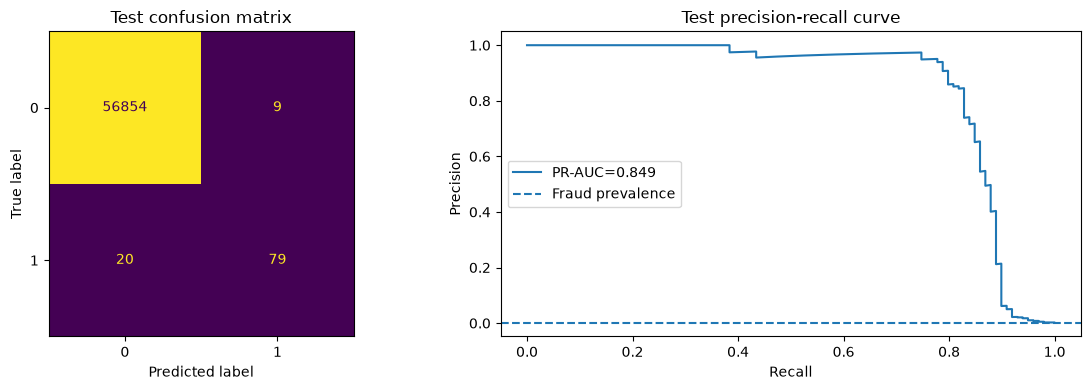

In [14]:
test_probabilities = model.predict_proba(X_test)[:, 1]
test_predictions = (test_probabilities >= threshold).astype(int)
test_pr_auc = float(average_precision_score(y_test, test_probabilities))
print("Selected model:", winner)
print(f"Test PR-AUC: {test_pr_auc:.4f}")
print("\nClassification report:\n")
print(classification_report(y_test, test_predictions, zero_division=0))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
ConfusionMatrixDisplay.from_predictions(y_test, test_predictions, ax=axes[0], colorbar=False)
axes[0].set_title("Test confusion matrix")
precisions, recalls, _ = precision_recall_curve(y_test, test_probabilities)
axes[1].plot(recalls, precisions, label=f"PR-AUC={test_pr_auc:.3f}")
axes[1].axhline(y=float(y_test.mean()), linestyle="--", label="Fraud prevalence")
axes[1].set(xlabel="Recall", ylabel="Precision", title="Test precision-recall curve")
axes[1].legend()
plt.tight_layout()
plt.show()

## 8. Save model, metrics and demo CSV
**This is the connection with the app.** The following files are used automatically by `backend/main.py` and the Streamlit dashboard:

- `artifacts/fraud_model.joblib` — trained model, feature order, optimal threshold
- `artifacts/metrics.json` — comparison and held-out test metrics
- `artifacts/demo_transactions.csv` — small *curated* example CSV for the upload screen, with `Class` omitted

The demo CSV deliberately includes more fraud examples than a natural sample; **do not treat it as an unbiased validation set**.

In [15]:
bundle = {
    "pipeline": model,
    "features": FEATURES,
    "threshold": threshold,
    "model_name": winner,
}
joblib.dump(bundle, ARTIFACT_DIR / "fraud_model.joblib")

metrics = {
    "model": winner,
    "model_comparison": validation_results,
    "threshold": threshold,
    "validation_pr_auc": validation_results[winner]["validation_pr_auc"],
    "test_pr_auc": test_pr_auc,
    "test_confusion_matrix": confusion_matrix(y_test, test_predictions).tolist(),
    "test_classification_report": classification_report(
        y_test, test_predictions, output_dict=True, zero_division=0
    ),
    "train_rows": int(len(X_train)),
    "validation_rows": int(len(X_valid)),
    "test_rows": int(len(X_test)),
    "features": FEATURES,
    "notice": "Retrospective random-split benchmark; not proof of production performance.",
}
(ARTIFACT_DIR / "metrics.json").write_text(
    json.dumps(metrics, indent=2), encoding="utf-8"
)

normal_demo = X_test.loc[y_test.eq(0)].sample(
    n=min(50, int(y_test.eq(0).sum())), random_state=RANDOM_STATE
)
fraud_demo = X_test.loc[y_test.eq(1)].sample(
    n=min(20, int(y_test.eq(1).sum())), random_state=RANDOM_STATE
)
pd.concat([normal_demo, fraud_demo]).sample(
    frac=1, random_state=RANDOM_STATE
).to_csv(ARTIFACT_DIR / "demo_transactions.csv", index=False)

for filename in ["fraud_model.joblib", "metrics.json", "demo_transactions.csv"]:
    print("Saved:", ARTIFACT_DIR / filename)

Saved: D:\Machine-learning-project\FraudShield-AI-One-Notebook\artifacts\fraud_model.joblib
Saved: D:\Machine-learning-project\FraudShield-AI-One-Notebook\artifacts\metrics.json
Saved: D:\Machine-learning-project\FraudShield-AI-One-Notebook\artifacts\demo_transactions.csv


## 9. SHAP explainability (optional but recommended)
This section explains **feature contributions** for a few test transactions. `V1`–`V28` are anonymized, so we cannot infer a specific real-world reason (like location or device) from their values. Contributions are **not probabilities or causal proof**.

If a particular SHAP/XGBoost version is incompatible, the model and metrics are **already saved** by the previous cell.

d:\Machine-learning-project\FraudShield-AI-One-Notebook\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


,SHAP contribution
V4,-2.883750
V12,-1.004924
V14,-0.999909
V11,-0.459422
V7,-0.355366
V13,-0.317630
V18,-0.313856
V28,-0.309191
V17,-0.285421
V19,-0.250318


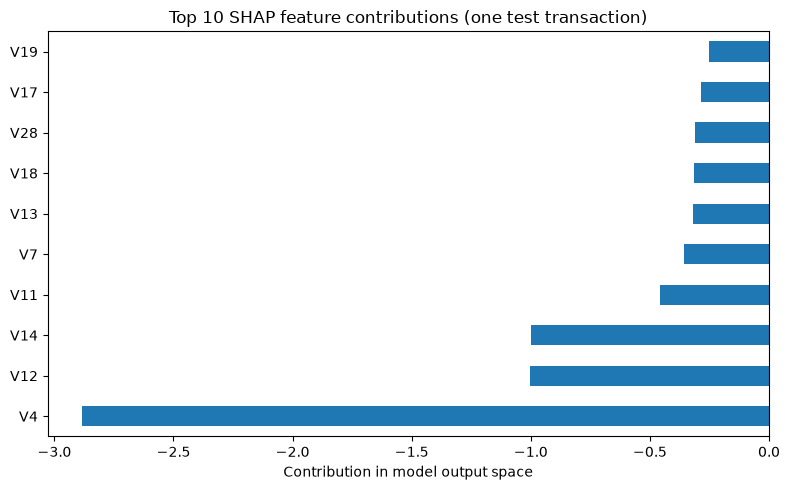

In [16]:
try:
    import shap
    example = X_test.iloc[[0]]
    if winner == "XGBoost":
        shap_values = shap.TreeExplainer(model)(example).values[0]
    else:
        scaler = model.named_steps["scaler"]
        classifier = model.named_steps["classifier"]
        background = scaler.transform(X_train.sample(n=min(100, len(X_train)), random_state=RANDOM_STATE))
        scaled_example = scaler.transform(example)
        shap_values = shap.LinearExplainer(classifier, background)(scaled_example).values[0]
    ranking = pd.Series(shap_values, index=FEATURES).reindex(
        pd.Series(abs(shap_values), index=FEATURES).sort_values(ascending=False).head(10).index
    )
    display(ranking.rename("SHAP contribution").to_frame())
    fig, ax = plt.subplots(figsize=(8, 5))
    ranking.sort_values().plot(kind="barh", ax=ax)
    ax.set_title("Top 10 SHAP feature contributions (one test transaction)")
    ax.set_xlabel("Contribution in model output space")
    plt.tight_layout()
    plt.show()
except Exception as exc:
    print("SHAP explanation skipped:", type(exc).__name__, str(exc)[:200])
    print("The saved ML model and dashboard will still work; check SHAP dependencies if needed.")

## 10. Verify the saved model — inference test
This final test loads the exact file that FastAPI reads. It performs one prediction without writing anything to PostgreSQL.

In [17]:
loaded = joblib.load(ARTIFACT_DIR / "fraud_model.joblib")
example_transaction = pd.read_csv(ARTIFACT_DIR / "demo_transactions.csv").head(1)
risk_score = float(loaded["pipeline"].predict_proba(
    example_transaction[loaded["features"]]
)[:, 1][0])
print("Loaded model:", loaded["model_name"])
print(f"Risk score: {risk_score:.4f}")
print("Flagged for review:", risk_score >= loaded["threshold"])
print("\nNext: start Docker PostgreSQL, FastAPI and Streamlit (see README.md).")

Loaded model: XGBoost
Risk score: 0.0018
Flagged for review: False

Next: start Docker PostgreSQL, FastAPI and Streamlit (see README.md).
